<a href="https://colab.research.google.com/github/cal-me-j/atf-ai-learn/blob/main/Week2_09_rag_101_retrieval_systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.4: RAG 101 - Retrieval Systems

## Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

## Learning Objectives
By the end of this notebook, you will:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!')
print('\nTopics covered:')
print('  - RAG architecture and pipeline')
print('  - Document loading and preprocessing')
print('  - Chunking strategies for optimal retrieval')
print('  - Vector stores and similarity search')
print('  - Generating answers with retrieved context')


✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!

Topics covered:
  - RAG architecture and pipeline
  - Document loading and preprocessing
  - Chunking strategies for optimal retrieval
  - Vector stores and similarity search
  - Generating answers with retrieved context


---
## Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [ ]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for RAG architecture and pipeline.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [2]:
# YOUR CODE HERE
# Complete the exercise following the instructions above

# Test your implementation
# Add test cases here
class SimpleDocumentPreprocessor:
    def __init__(self):
        self.documents = []

    def add_and_clean_document(self, text: str) -> str:
        """
        Cleans, validates, and stores a document.
        """
        # 1. Parameter Validation & Edge Case Handling
        if not isinstance(text, str):
            raise TypeError("Document must be a string.")

        # 2. Text Normalization
        cleaned_text = text.strip()
        cleaned_text = re.sub(r'\s+', ' ', cleaned_text) # Collapse multiple spaces/newlines

        if len(cleaned_text) < 3:
            raise ValueError("Document is too short to be processed (minimum 3 characters).")

        # 3. Store and return
        self.documents.append(cleaned_text)
        return cleaned_text

# --- Test Cases ---
try:
    preprocessor = SimpleDocumentPreprocessor()

    # Test 1: Normal input
    doc1 = "   Welcome to  RAG  101!   Let's   learn  retrieval.   "
    cleaned = preprocessor.add_and_clean_document(doc1)
    print(f"✅ Test 1 Passed! Cleaned result: '{cleaned}'")

    # Test 2: Edge Case - Too short
    print("\nTesting Edge Case (Too Short):")
    preprocessor.add_and_clean_document("  Hi ")  # This should pass
    preprocessor.add_and_clean_document(" ")      # This should raise ValueError

except ValueError as e:
    print(f"❌ Expected failure handled successfully: {e}")
except Exception as e:
    print(f"🔥 Unexpected error: {e}")

pass  # Replace with your implementation

✅ Test 1 Passed! Cleaned result: 'Welcome to RAG 101! Let's learn retrieval.'

Testing Edge Case (Too Short):
❌ Expected failure handled successfully: Document is too short to be processed (minimum 3 characters).


---
## Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Document loading and preprocessing.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [3]:
# YOUR CODE HERE
# Implement the intermediate exercise
class DocumentLoaderAndExtractor:
    def __init__(self):
        self.processed_documents = []

    def clean_text(self, text: str) -> str:
        """
        Reuses text normalization logic from Exercise 1.
        """
        if not isinstance(text, str):
            raise TypeError("Document content must be a string.")
        cleaned = text.strip()
        cleaned = re.sub(r'\s+', ' ', cleaned)
        if len(cleaned) < 3:
            raise ValueError("Document content is too short (minimum 3 characters required).")
        return cleaned

    def load_and_process(self, raw_doc: Any) -> Dict[str, Any]:
        """
        Validates inputs, extracts metadata, and stores the processed document.
        """
        # 1. Parameter Validation & Multi-Format Handling
        if isinstance(raw_doc, str):
            content = raw_doc
            source = "Unknown Source"
        elif isinstance(raw_doc, dict):
            if 'content' not in raw_doc:
                raise KeyError("Dictionary document must contain a 'content' key.")
            content = raw_doc['content']
            source = raw_doc.get('source', "Anonymous Dict")
        else:
            raise TypeError("Unsupported document format. Must be a string or a dictionary.")

        # 2. Text Preprocessing
        cleaned_content = self.clean_text(content)

        # 3. Metadata Extraction
        word_count = len(cleaned_content.split())
        char_count = len(cleaned_content)
        # Estimate reading time (average 200 words per minute)
        estimated_reading_time_sec = round((word_count / 200) * 60, 2)

        processed_doc = {
            'source': source,
            'cleaned_content': cleaned_content,
            'metadata': {
                'word_count': word_count,
                'char_count': char_count,
                'estimated_reading_time_seconds': estimated_reading_time_sec
            }
        }

        self.processed_documents.append(processed_doc)
        return processed_doc

# --- Test Cases ---
try:
    loader = DocumentLoaderAndExtractor()

    # Test 1: Testing String Input
    doc1 = "   Retrieval-Augmented Generation is a powerful framework.   "
    res1 = loader.load_and_process(doc1)
    print("✅ Test 1 (String Input) Passed:")
    print(json.dumps(res1, indent=2))

    # Test 2: Testing Dictionary Input with metadata
    doc2 = {
        "source": "RAG_Handbook_Ch1.txt",
        "content": "Embedding models represent words, phrases, or documents as vectors in a high-dimensional space."
    }
    res2 = loader.load_and_process(doc2)
    print("\n✅ Test 2 (Dict Input with Metadata) Passed:")
    print(json.dumps(res2, indent=2))

    # Test 3: Testing Unsupported Format
    print("\nTesting Unsupported Input Type:")
    loader.load_and_process(12345)

except (TypeError, ValueError, KeyError) as e:
    print(f"❌ Expected failure handled successfully: {e}")
except Exception as e:
    print(f"🔥 Unexpected error: {e}")

pass  # Replace with your implementation

✅ Test 1 (String Input) Passed:
{
  "source": "Unknown Source",
  "cleaned_content": "Retrieval-Augmented Generation is a powerful framework.",
  "metadata": {
    "word_count": 6,
    "char_count": 55,
    "estimated_reading_time_seconds": 1.8
  }
}

✅ Test 2 (Dict Input with Metadata) Passed:
{
  "source": "RAG_Handbook_Ch1.txt",
  "cleaned_content": "Embedding models represent words, phrases, or documents as vectors in a high-dimensional space.",
  "metadata": {
    "word_count": 13,
    "char_count": 95,
    "estimated_reading_time_seconds": 3.9
  }
}

Testing Unsupported Input Type:
❌ Expected failure handled successfully: Unsupported document format. Must be a string or a dictionary.


---
## Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

✅ Successfully chunked and indexed 4 chunks.

🔍 Query: 'semantic vectors querying'
Top Retrieved Chunks:
  - [Score: 0.1818] doc_2_chunk_0: "Embeddings translate textual concepts into vectors for semantic vector database "
  - [Score: 0.0000] doc_1_chunk_0: "Retrieval-Augmented Generation processes documents to augment LLM system context"

📊 Displaying Visual Metrics:


/tmp/ipykernel_968/858733306.py:93: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(chunk_ids, rotation=45, ha='right')


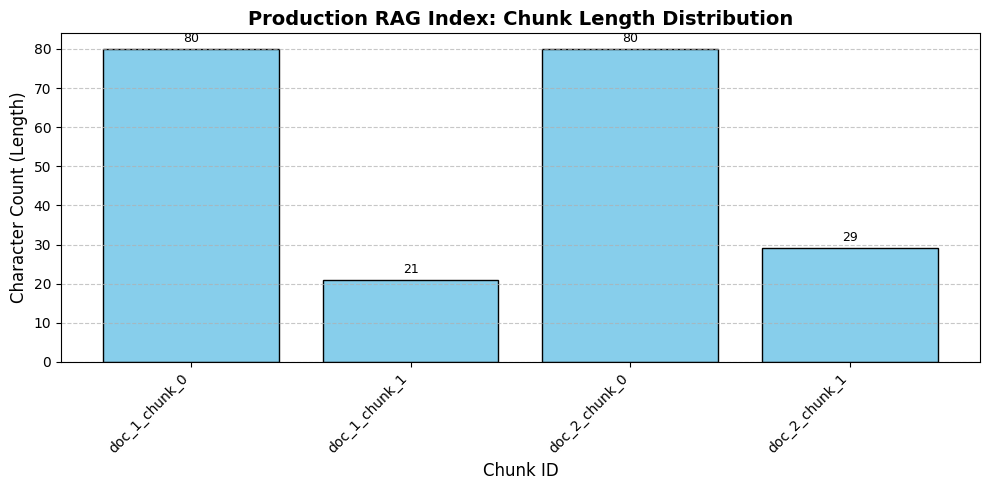

In [4]:
# YOUR CODE HERE
# Build your complete implementation

import re
import matplotlib.pyplot as plt
from typing import List, Dict, Any, Tuple

class ProductionRAGSystem:
    """
    A production-ready chunking, indexing, and mock retrieval system with visualization capabilities.
    """
    def __init__(self, chunk_size: int = 50, chunk_overlap: int = 15):
        if chunk_size <= chunk_overlap:
            raise ValueError("chunk_size must be strictly greater than chunk_overlap.")
        self.chunk_size = chunk_size
        self.chunk_overlap = chunk_overlap
        self.chunks_db = [] # Acts as our document chunk vector index

    def clean_text(self, text: str) -> str:
        if not isinstance(text, str):
            raise TypeError("Text content must be a string.")
        cleaned = text.strip()
        return re.sub(r'\s+', ' ', cleaned)

    def add_document(self, doc_id: str, text: str):
        """
        Cleans and splits a document into overlapping chunks, then indexes them.
        """
        cleaned = self.clean_text(text)
        if not cleaned:
            return

        # Sliding window chunking
        start = 0
        chunk_index = 0
        while start < len(cleaned):
            end = start + self.chunk_size
            chunk_text = cleaned[start:end]

            self.chunks_db.append({
                "chunk_id": f"{doc_id}_chunk_{chunk_index}",
                "doc_id": doc_id,
                "text": chunk_text,
                "length": len(chunk_text)
            })

            if end >= len(cleaned):
                break
            start += (self.chunk_size - self.chunk_overlap)
            chunk_index += 1

    def retrieve(self, query: str, top_k: int = 3) -> List[Tuple[Dict[str, Any], float]]:
        """
        Retrieves chunks using a mock similarity scoring system (keyword intersection over union).
        """
        query_words = set(self.clean_text(query).lower().split())
        results = []

        for chunk in self.chunks_db:
            chunk_words = set(chunk["text"].lower().split())
            if not query_words:
                score = 0.0
            else:
                # Jaccard Similarity as mock semantic similarity score
                intersection = query_words.intersection(chunk_words)
                union = query_words.union(chunk_words)
                score = round(len(intersection) / len(union), 4) if union else 0.0

            results.append((chunk, score))

        # Sort by score descending
        results.sort(key=lambda x: x[1], reverse=True)
        return results[:top_k]

    def visualize_index_metrics(self):
        """
        Visualizes chunk lengths across our vector database index.
        """
        if not self.chunks_db:
            print("⚠️ No chunks indexed to visualize.")
            return

        chunk_ids = [c["chunk_id"] for c in self.chunks_db]
        lengths = [c["length"] for c in self.chunks_db]

        fig, ax = plt.subplots(figsize=(10, 5))
        bars = ax.bar(chunk_ids, lengths, color='skyblue', edgecolor='black')

        # Styling
        ax.set_title('Production RAG Index: Chunk Length Distribution', fontsize=14, fontweight='bold')
        ax.set_xlabel('Chunk ID', fontsize=12)
        ax.set_ylabel('Character Count (Length)', fontsize=12)
        ax.set_xticklabels(chunk_ids, rotation=45, ha='right')
        ax.grid(axis='y', linestyle='--', alpha=0.7)

        # Annotating bar heights
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f'{height}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9)

        plt.tight_layout()
        plt.show()

# --- Test Cases ---
try:
    # Initialize system with chunk_size of 80 characters and 20 overlap
    rag_system = ProductionRAGSystem(chunk_size=80, chunk_overlap=20)

    # Add documents
    rag_system.add_document("doc_1", "Retrieval-Augmented Generation processes documents to augment LLM system context.")
    rag_system.add_document("doc_2", "Embeddings translate textual concepts into vectors for semantic vector database querying.")

    print(f"✅ Successfully chunked and indexed {len(rag_system.chunks_db)} chunks.")

    # Test Retrieve
    query = "semantic vectors querying"
    retrieved = rag_system.retrieve(query, top_k=2)

    print(f"\n🔍 Query: '{query}'")
    print("Top Retrieved Chunks:")
    for match, score in retrieved:
        print(f"  - [Score: {score:.4f}] {match['chunk_id']}: \"{match['text']}\"")

    # Visualize chunk statistics
    print("\n📊 Displaying Visual Metrics:")
    rag_system.visualize_index_metrics()

except Exception as e:
    print(f"🔥 System execution error: {e}")

# Test your production system
# Add comprehensive tests here

---
## Summary & Key Takeaways

### What We Learned:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code